<a href="https://colab.research.google.com/github/Murcha1990/ML_AI26/blob/main/Week4_Classification/GradientDescentPro.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Градиентный спуск: векторная реализация, липшицевость и метод моментов

## План занятия

1. Векторная реализация градиентного спуска для линейной регрессии
2. Липшицевость функции и её градиента: примеры, демо и влияние на сходимость
3. Градиентный спуск с моментом (Momentum, Nesterov): реализация в виде класса и сравнение с обычным GD
4. Модификации градиентного спуска в sklearn

## Зачем мы это разбираем

Если честно, в типичных задачах классического ML на табличных данных писать градиентный спуск руками и настраивать момент не нужно.

* `LinearRegression` находит решение точно, без итераций.
* `LogisticRegression` использует готовые солверы (`lbfgs`, `newton-cg`, `saga`). Они сами подбирают шаг на каждой итерации.
* Градиентный бустинг (CatBoost, LightGBM, XGBoost) устроен иначе, хотя его `learning_rate` — это тоже шаг градиентного спуска, только в пространстве функций.
* Если данных так много, что они не помещаются в память, берут `SGDRegressor` / `SGDClassifier`. Обычно хватает простого SGD на стандартизованных признаках с расписанием шага по умолчанию. Момента там нет, и он не нужен.

Зачем тогда разбираться так подробно:

1. **Диагностика.** Если ошибка растёт или обучение стоит на месте, почти всегда виноваты шаг или масштаб признаков. Липшицевость градиента объясняет оба практических правила: «шаг порядка $1/L$» и «сначала стандартизуй признаки».
2. **Нейросети.** Любая нейросеть обучается градиентным спуском, и там решения приходится принимать самим: SGD с моментом или Adam, `momentum=0.9`, расписание шага, ограничение нормы градиента (gradient clipping). Всё это проще понять на линейной регрессии, где видна каждая деталь.
3. **Параметры библиотек.** `eta0`, `learning_rate`, `momentum`, `beta_1` в sklearn и PyTorch перестают быть магическими числами.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

# 1. Векторная реализация градиентного спуска

Сгенерируем выборку для задачи регрессии и визуализируем данные.

(100, 1) (100,)


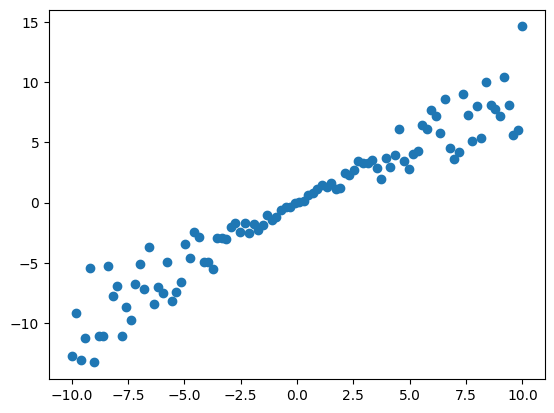

In [ ]:
rng = np.random.default_rng(42)

X = np.linspace(-10, 10, 100)
y = X * (rng.random(len(X)) + 0.5)
X = X.reshape(-1, 1)   # матрица объект-признак размера (100, 1)

print(X.shape, y.shape)

plt.scatter(X, y);

Функция потерь — среднеквадратичная ошибка в матричном виде:

$$Q(w) = MSE = \frac{1}{m}\|Xw - y\|^2_2$$

* $X$ — матрица объект-признак, $m$ — число объектов, $w$ — вектор весов модели;
* $Xw$ — вектор предсказаний модели;
* $y$ — вектор правильных ответов.

Норму вектора посчитаем функцией `np.linalg.norm`.

In [ ]:
def compute_cost(X, y, w):
    m = len(y)
    return (1. / m) * np.linalg.norm(X @ w - y) ** 2

Градиент MSE:

$$\nabla_w Q(w)=\frac{2}{m}X^T(Xw-y)$$

Шаг градиентного спуска с шагом (learning rate) $\lambda$:

$$w_{new} = w_{prev} - \lambda\nabla_w Q(w_{prev})$$

Реализуем метод:

* добавим к матрице $X$ столбец из единиц — константный признак. Он позволяет записать предсказание линейной регрессии как скалярное произведение и избавиться от знака суммы:
$a(x)=w_0+w_1x_1+\dots+w_dx_d=w_0\cdot 1+w_1x_1+\dots+w_dx_d=\langle w,x \rangle$ (в Python: `w @ x`);
* инициализируем случайным образом вектор весов `w`;
* в массив `cost_track` записываем ошибку на каждой итерации;
* в цикле по числу итераций обновляем веса по формуле градиентного спуска.

In [ ]:
def add_ones(X):
    return np.hstack((np.ones((X.shape[0], 1)), X))


def gradient_descent(X, y, learning_rate, iterations, seed=0):
    X = add_ones(X)
    w = np.random.default_rng(seed).random(X.shape[1])
    m = X.shape[0]

    cost_track = np.zeros(iterations)

    for i in range(iterations):
        w = w - learning_rate * 2. / m * X.T @ (X @ w - y)
        cost_track[i] = compute_cost(X, y, w)

    return cost_track, w


def predict(X, w):
    return add_ones(X) @ w

Применим градиентный спуск.

Веса: [-0.21858438  0.99867427]


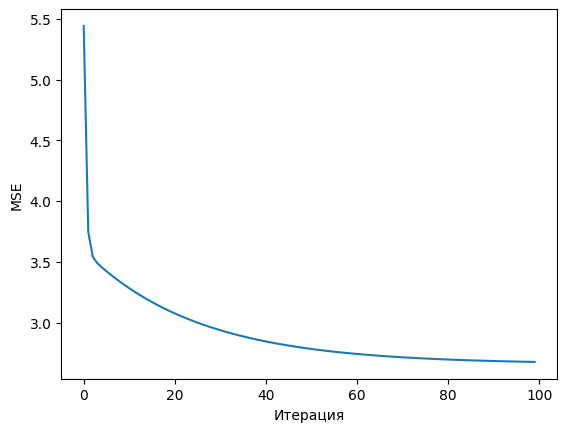

In [ ]:
track, weights = gradient_descent(X, y, 0.01, 100)
print('Веса:', weights)

plt.plot(track)
plt.xlabel('Итерация')
plt.ylabel('MSE');

Добавим к графику полученную регрессионную прямую.

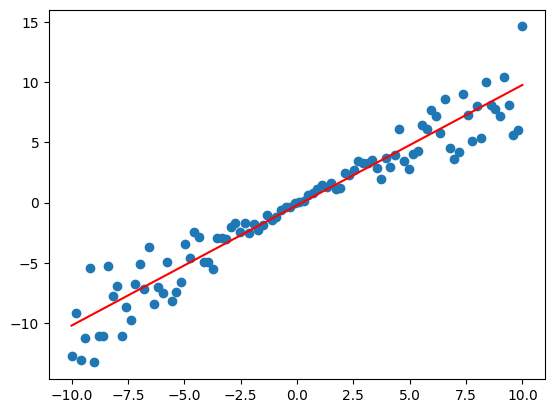

In [ ]:
pred = predict(X, weights)

plt.scatter(X, y)
plt.plot(X, pred, '-', c='r');

Почему шаг 0.01 работает, а, например, 0.05 — нет? Ответ даёт **липшицевость градиента**.

In [ ]:
track_big, _ = gradient_descent(X, y, 0.05, 10)
print(track_big)

[1.07570795e+02 6.03389418e+02 3.46164920e+03 1.99350664e+04
 1.14875691e+05 6.62041005e+05 3.81548239e+06 2.19894994e+07
 1.26730590e+08 7.30377878e+08]


# 2. Липшицевость и сходимость градиентного спуска

## Определения

Функция $f$ называется **липшицевой** с константой $L$, если

$$|f(x) - f(y)| \le L\,|x - y| \quad \text{для всех } x, y.$$

Смысл: функция не может меняться быстрее, чем с «наклоном» $L$. Для дифференцируемой функции это то же самое, что $|f'(x)| \le L$.

Для градиентного спуска важнее другое свойство — **липшицевость градиента** (такие функции называют **$L$-гладкими**):

$$\|\nabla f(x) - \nabla f(y)\| \le L\,\|x - y\|.$$

Смысл: градиент не может меняться слишком резко, то есть **кривизна функции ограничена**. Для дважды дифференцируемой функции одной переменной это значит $|f''(x)| \le L$, а в многомерном случае — что собственные числа матрицы Гессе по модулю не больше $L$.

## Что это даёт градиентному спуску

Если градиент $L$-липшицев, то:

* при шаге $\lambda \le 1/L$ функция **гарантированно убывает** на каждой итерации:
$f(x_{k+1}) \le f(x_k) - \frac{1}{2L}\|\nabla f(x_k)\|^2$;
* для выпуклой функции градиентный спуск сходится при любом шаге $0 < \lambda < 2/L$;
* для квадратичной функции (например, MSE линейной регрессии) граница $2/L$ точная: при $\lambda > 2/L$ метод **расходится**.

Итого: $L$ — это «максимальная кривизна» функции, а $1/L$ — естественный масштаб шага.

## Примеры

| Функция | $f$ липшицева? | $\nabla f$ липшицев? | Комментарий |
|---|---|---|---|
| $x^2$ | нет (глобально) | да, $L=2$ | эталонный «хороший» случай |
| $\lvert x\rvert$ | да, $L=1$ | нет | производная скачет в нуле |
| $x^4$ | нет | нет (глобально) | кривизна $12x^2$ растёт с удалением от нуля |
| функция Хьюбера | да, $L=\delta$ | да, $L=1$ | «сглаженный» модуль, robust-регрессия |
| $\log(1+e^{-z})$ (logloss) | да, $L=1$ | да, $L=1/4$ | поэтому логрегрессия хорошо оптимизируется |
| MSE линейной регрессии | нет | да, $L=\frac{2}{m}\lambda_{\max}(X^TX)$ | $L$ зависит от данных |

Нарисуем первые четыре функции и их производные.

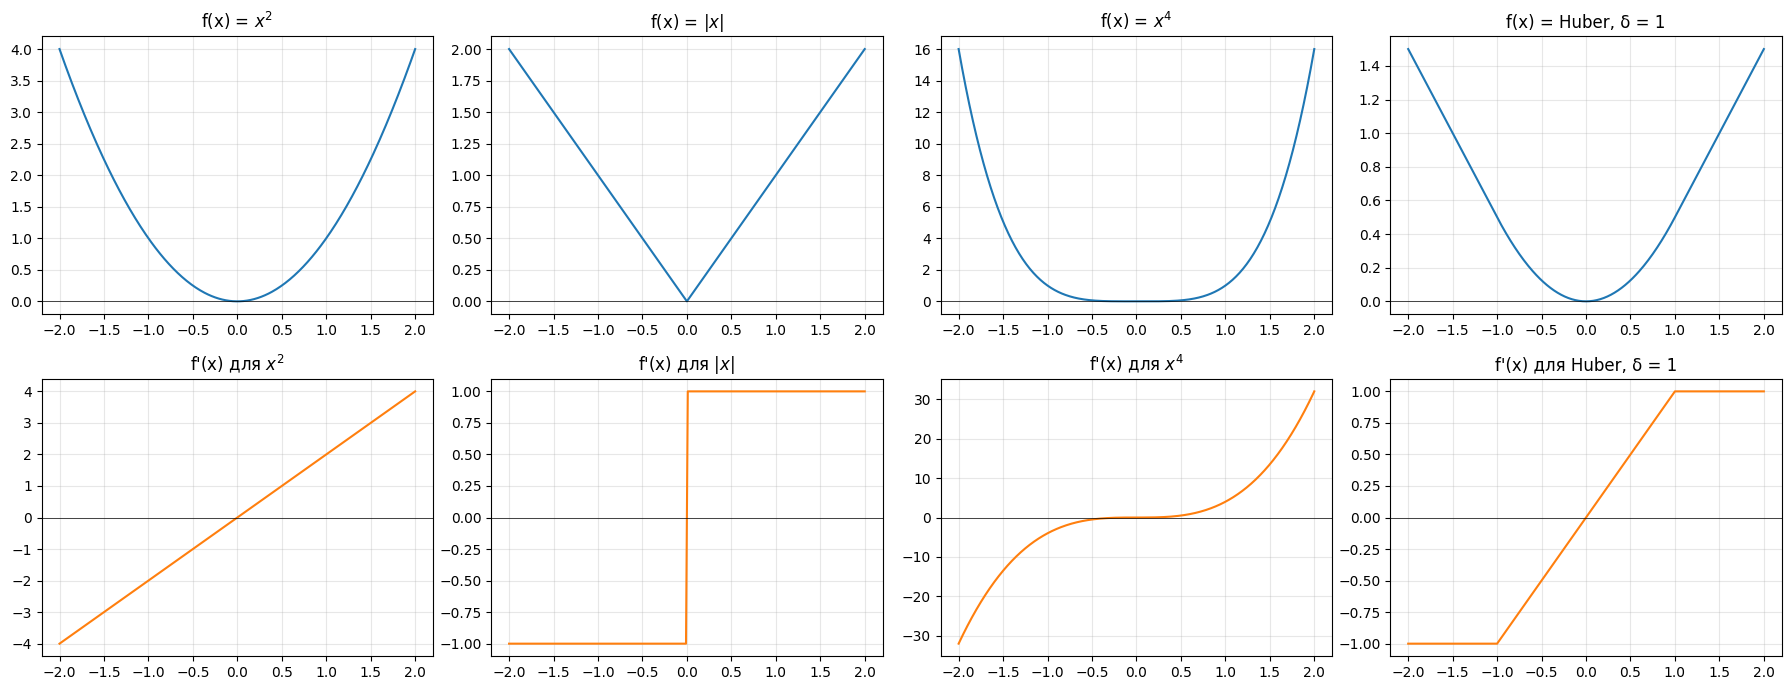

In [ ]:
def huber(x, delta=1.0):
    return np.where(np.abs(x) <= delta, 0.5 * x**2, delta * (np.abs(x) - 0.5 * delta))

def huber_grad(x, delta=1.0):
    return np.clip(x, -delta, delta)

examples = {
    '$x^2$':        (lambda x: x**2,      lambda x: 2 * x),
    '$|x|$':        (np.abs,              np.sign),
    '$x^4$':        (lambda x: x**4,      lambda x: 4 * x**3),
    'Huber, δ = 1': (huber,               huber_grad),
}

xs = np.linspace(-2, 2, 401)
fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for j, (name, (func, grad)) in enumerate(examples.items()):
    axes[0, j].plot(xs, func(xs))
    axes[0, j].set_title(f'f(x) = {name}')
    axes[1, j].plot(xs, grad(xs), c='C1')
    axes[1, j].set_title(f"f'(x) для {name}")
    for ax in axes[:, j]:
        ax.grid(alpha=0.3)
        ax.axhline(0, c='black', lw=0.5)
plt.tight_layout()
plt.show()

По нижнему ряду видно:
* у $x^2$ и у функции Хьюбера производная меняется не быстрее, чем прямая с наклоном $L$ → градиент липшицев;
* у $|x|$ производная прыгает с −1 на 1 → градиент не липшицев (и даже не непрерывен);
* у $x^4$ производная становится всё круче → на всей прямой константы $L$ нет.

## Демо 1. Оценим константу Липшица численно

Константу Липшица градиента можно оценить «в лоб»: взять много случайных пар точек и найти максимум отношения $\frac{|f'(x) - f'(y)|}{|x - y|}$.

In [ ]:
def estimate_lipschitz(func, R, n_pairs=100_000, seed=0):
    rng = np.random.default_rng(seed)
    a = rng.uniform(-R, R, n_pairs)
    b = rng.uniform(-R, R, n_pairs)
    mask = np.abs(a - b) > 1e-9
    return np.max(np.abs(func(a[mask]) - func(b[mask])) / np.abs(a[mask] - b[mask]))

for name, (func, grad) in examples.items():
    estimates = [estimate_lipschitz(grad, R) for R in [1, 2, 5]]
    print(f'{name:>13}:  L(∇f) на [-1,1], [-2,2], [-5,5] ≈ ' + ', '.join(f'{e:10.1f}' for e in estimates))

        $x^2$:  L(∇f) на [-1,1], [-2,2], [-5,5] ≈        2.0,        2.0,        2.0
        $|x|$:  L(∇f) на [-1,1], [-2,2], [-5,5] ≈      544.2,      272.1,      108.8
        $x^4$:  L(∇f) на [-1,1], [-2,2], [-5,5] ≈       11.9,       47.5,      297.0
 Huber, δ = 1:  L(∇f) на [-1,1], [-2,2], [-5,5] ≈        1.0,        1.0,        1.0


* для $x^2$ и Хьюбера оценка не зависит от отрезка — это настоящая константа $L$ (2 и 1);
* для $x^4$ оценка растёт как $12R^2$ — глобальной константы нет;
* для $|x|$ оценка огромная и растёт при уменьшении расстояния между точками — разрыв производной.

## Демо 2. $f(x) = x^2$: шаг относительно $1/L$

Здесь $L = 2$. Запустим градиентный спуск с шагами $0.2/L$, $1/L$, $1.8/L$, $2/L$ и $2.1/L$.

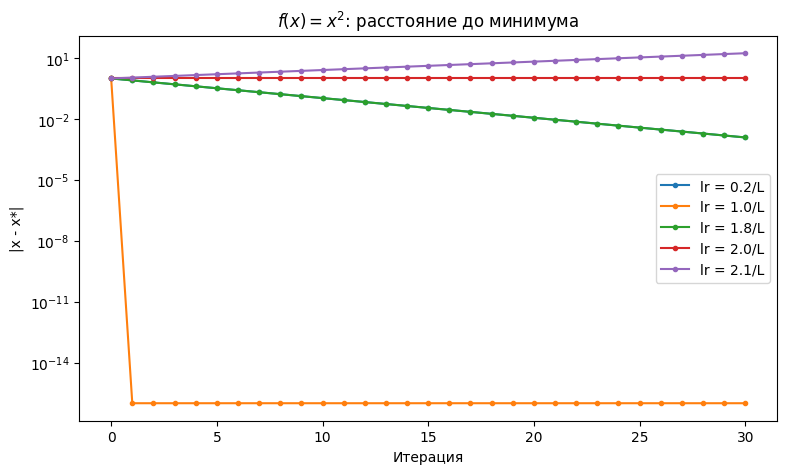

In [ ]:
def gd_1d(grad, x0, lr, n_iter=30):
    xs = [x0]
    for _ in range(n_iter):
        xs.append(xs[-1] - lr * grad(xs[-1]))
    return np.array(xs)

L = 2
plt.figure(figsize=(9, 5))
for k in [0.2, 1.0, 1.8, 2.0, 2.1]:
    trace = gd_1d(lambda x: 2 * x, x0=1.0, lr=k / L)
    plt.plot(np.abs(trace) + 1e-16, 'o-', ms=3, label=f'lr = {k}/L')
plt.yscale('log')
plt.xlabel('Итерация')
plt.ylabel('|x - x*|')
plt.title('$f(x)=x^2$: расстояние до минимума')
plt.legend()
plt.show()

* $\lambda = 1/L$ для квадратичной функции попадает в минимум за один шаг;
* $\lambda = 1.8/L$ — сходится, но с осцилляциями (точка прыгает через минимум);
* $\lambda = 2/L$ — бесконечные колебания между $1$ и $-1$;
* $\lambda > 2/L$ — расходимость.

## Демо 3. $f(x) = |x|$: градиент не липшицев

При постоянном шаге градиентный спуск на $|x|$ **не сходится**: вблизи нуля градиент всё равно равен $\pm 1$, и точка бесконечно прыгает вокруг минимума с амплитудой порядка шага. Помогает только **убывающий шаг**, например $\lambda_k = \lambda_0/\sqrt{k}$ (это классический субградиентный метод).

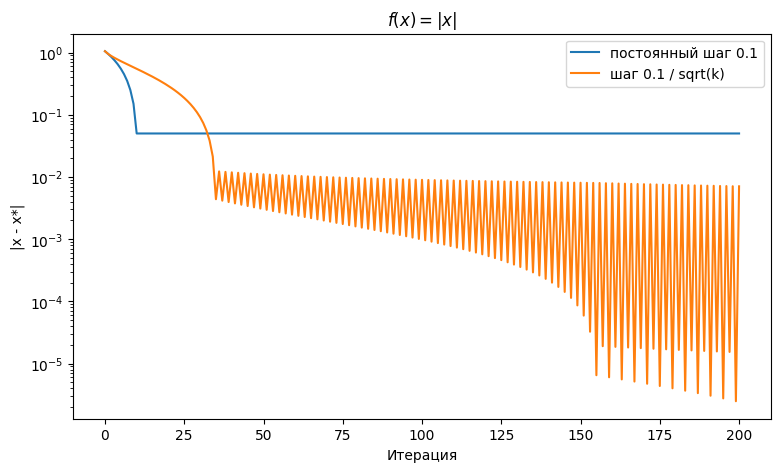

In [ ]:
def gd_1d_schedule(grad, x0, lr_fn, n_iter=200):
    xs = [x0]
    for k in range(1, n_iter + 1):
        xs.append(xs[-1] - lr_fn(k) * grad(xs[-1]))
    return np.array(xs)

const = gd_1d_schedule(np.sign, x0=1.05, lr_fn=lambda k: 0.1)
decay = gd_1d_schedule(np.sign, x0=1.05, lr_fn=lambda k: 0.1 / np.sqrt(k))

plt.figure(figsize=(9, 5))
plt.plot(np.abs(const), label='постоянный шаг 0.1')
plt.plot(np.abs(decay), label='шаг 0.1 / sqrt(k)')
plt.yscale('log')
plt.xlabel('Итерация')
plt.ylabel('|x - x*|')
plt.title('$f(x)=|x|$')
plt.legend()
plt.show()

Именно поэтому для негладких функций потерь (L1-регуляризация, hinge loss в SVM) используют убывающий шаг. В `SGDRegressor` и `SGDClassifier` за это отвечают расписания `learning_rate='invscaling'` и `'optimal'`.

## Демо 4. $f(x) = x^4$: градиент липшицев только локально

Кривизна $f''(x) = 12x^2$ зависит от точки. Возьмём постоянный шаг $\lambda = 0.1$. Вблизи $x = 1$ локальная константа $L \approx 12$, и $\lambda < 2/L$. Вблизи $x = 3$ уже $L \approx 108$, и тот же шаг оказывается слишком большим.

In [ ]:
grad_x4 = lambda x: 4 * x**3

for x0 in [1.0, 3.0]:
    trace = gd_1d(grad_x4, x0=x0, lr=0.1, n_iter=5)
    print(f'x0 = {x0}:', np.array2string(trace, precision=3))

x0 = 1.0: [1.    0.6   0.514 0.459 0.421 0.391]
x0 = 3.0: [ 3.000e+00 -7.800e+00  1.820e+02 -2.412e+06  5.613e+18 -7.075e+55]


Из $x_0 = 3$ метод улетает в бесконечность за пару шагов: постоянный шаг, подходящий для одной области, в другой оказывается слишком большим. Поэтому для функций без глобальной константы Липшица шаг нужно подстраивать под локальную кривизну или начинать оптимизацию ближе к минимуму.

## Демо 5. Линейная регрессия: $L$ считается по данным

Для MSE матрица Гессе постоянна: $H = \frac{2}{m}X^TX$. Поэтому константа Липшица градиента равна её наибольшему собственному числу:

$$L = \frac{2}{m}\lambda_{\max}(X^TX).$$

Посчитаем $L$ для наших данных (с учётом столбца из единиц) и проверим теорию.

In [ ]:
X1 = add_ones(X)
H = 2 / len(y) * X1.T @ X1
eigvals = np.linalg.eigvalsh(H)
L_reg = eigvals.max()

print(f'L = {L_reg:.2f}  ->  безопасный шаг 1/L = {1 / L_reg:.4f}, граница сходимости 2/L = {2 / L_reg:.4f}')
print('Шаг 0.01 из первой части:', 'меньше 2/L' if 0.01 < 2 / L_reg else 'больше 2/L')

L = 68.01  ->  безопасный шаг 1/L = 0.0147, граница сходимости 2/L = 0.0294
Шаг 0.01 из первой части: меньше 2/L


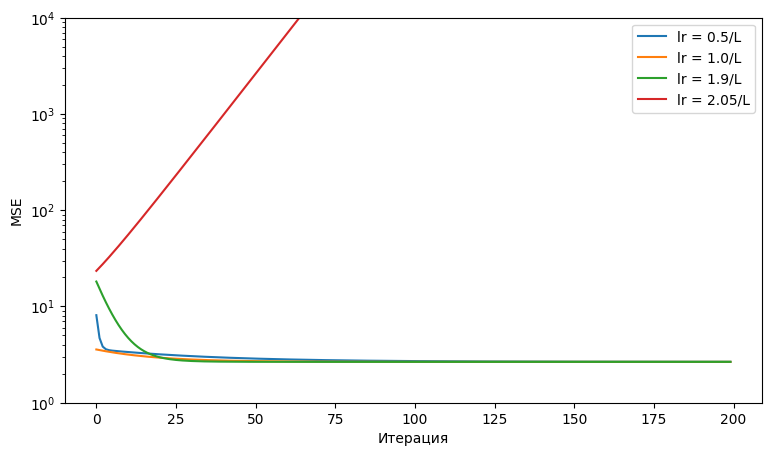

In [ ]:
plt.figure(figsize=(9, 5))
for k in [0.5, 1.0, 1.9, 2.05]:
    track, _ = gradient_descent(X, y, learning_rate=k / L_reg, iterations=200)
    plt.plot(track, label=f'lr = {k}/L')
plt.yscale('log')
plt.ylim(1, 1e4)
plt.xlabel('Итерация')
plt.ylabel('MSE')
plt.legend()
plt.show()

Граница $2/L$ работает точно: шаг $1.9/L$ ещё сходится, а $2.05/L$ уже расходится.

Отсюда же видно, почему важен масштаб признаков: $L \approx 68$ получилось потому, что признак $x$ принимает значения до $\pm 10$. Проверим, что будет после стандартизации.

In [ ]:
X1_scaled = add_ones((X - X.mean()) / X.std())
L_scaled = np.linalg.eigvalsh(2 / len(y) * X1_scaled.T @ X1_scaled).max()
print(f'После стандартизации: L = {L_scaled:.2f}, граница сходимости 2/L = {2 / L_scaled:.2f}')

После стандартизации: L = 2.00, граница сходимости 2/L = 1.00


После стандартизации граница сходимости — шаг 1, а не 0.03: можно шагать в 30 с лишним раз смелее.

Но и на стандартизованных данных функция потерь может быть похожа на **вытянутый овраг**: по одному направлению она очень крутая, по другому — почти плоская. Так бывает, например, когда признаки сильно коррелированы. Шаг ограничен крутым направлением (через $L$), и вдоль пологого дна оврага градиентный спуск ползёт очень медленно. Здесь помогает метод моментов.

# 3. Градиентный спуск с моментом

## Идея

**Momentum (метод тяжёлого шарика, Поляк, 1964).** Представим шарик, который катится по поверхности функции потерь. Он накапливает скорость: в направлениях, где градиент стабильно указывает в одну сторону, шарик разгоняется, а в направлениях, где градиент меняет знак (зигзаги), колебания взаимно гасятся.

$$v_{k+1} = \beta v_k - \lambda\nabla f(w_k), \qquad w_{k+1} = w_k + v_{k+1}$$

* $v$ — «скорость», экспоненциально сглаженная сумма прошлых градиентов;
* $\beta \in [0, 1)$ — коэффициент момента (обычно 0.9). При $\beta = 0$ получаем обычный GD.

**Nesterov Accelerated Gradient (1983).** Градиент считается не в текущей точке, а в точке, куда нас уже «несёт» скорость:

$$v_{k+1} = \beta v_k - \lambda\nabla f(w_k + \beta v_k), \qquad w_{k+1} = w_k + v_{k+1}$$

Это позволяет заранее «притормозить» перед минимумом.

**Почему это быстрее.** Вдоль пологого дна оврага градиент маленький, но всё время указывает в одну сторону. Скорость накапливается, и шаги вдоль оврага становятся длиннее. Поперёк оврага градиент меняет знак, и вклады прошлых шагов частично взаимно сокращаются.

## Реализация в виде класса

Напишем класс в стиле sklearn: методы `fit` и `predict`, атрибуты `coef_` и `intercept_`. Дополнительно будем сохранять историю ошибки и весов, чтобы сравнивать методы.

In [ ]:
import warnings


class GDRegressor:
    """Линейная регрессия (MSE), обучаемая градиентным спуском.

    momentum = 0                  -> обычный градиентный спуск
    momentum > 0                  -> метод моментов (heavy ball)
    momentum > 0, nesterov=True   -> ускоренный градиент Нестерова
    """

    def __init__(self, learning_rate=0.01, momentum=0.0, nesterov=False,
                 n_iter=1000, tol=None, fit_intercept=True):
        self.learning_rate = learning_rate
        self.momentum = momentum
        self.nesterov = nesterov
        self.n_iter = n_iter
        self.tol = tol
        self.fit_intercept = fit_intercept

    def _design_matrix(self, X):
        X = np.asarray(X, dtype=float)
        if self.fit_intercept:
            X = np.hstack((np.ones((X.shape[0], 1)), X))
        return X

    @staticmethod
    def _loss(X, y, w):
        return np.mean((X @ w - y) ** 2)

    @staticmethod
    def _grad(X, y, w):
        return 2. / len(y) * X.T @ (X @ w - y)

    def fit(self, X, y, w_init=None):
        X = self._design_matrix(X)
        y = np.asarray(y, dtype=float)

        w = np.zeros(X.shape[1]) if w_init is None else np.array(w_init, dtype=float)
        v = np.zeros_like(w)

        self.loss_history_ = [self._loss(X, y, w)]
        self.weights_history_ = [w.copy()]

        for i in range(self.n_iter):
            point = w + self.momentum * v if self.nesterov else w
            g = self._grad(X, y, point)

            v = self.momentum * v - self.learning_rate * g
            w = w + v

            loss = self._loss(X, y, w)
            self.loss_history_.append(loss)
            self.weights_history_.append(w.copy())

            if not np.isfinite(loss):
                warnings.warn(f'Метод разошёлся на итерации {i + 1}: уменьшите learning_rate')
                break
            if self.tol is not None and np.linalg.norm(g) < self.tol:
                break

        self.n_iter_ = i + 1
        self.loss_history_ = np.array(self.loss_history_)
        self.weights_history_ = np.array(self.weights_history_)

        if self.fit_intercept:
            self.intercept_, self.coef_ = w[0], w[1:]
        else:
            self.intercept_, self.coef_ = 0.0, w
        return self

    def predict(self, X):
        return np.asarray(X, dtype=float) @ self.coef_ + self.intercept_

Проверим, что при `momentum=0` класс даёт тот же результат, что функция из первой части, и совпадает с `LinearRegression`.

In [ ]:
from sklearn.linear_model import LinearRegression

model = GDRegressor(learning_rate=0.01, n_iter=2000).fit(X, y)
lin = LinearRegression().fit(X, y)

print('GDRegressor:      ', model.intercept_, model.coef_)
print('LinearRegression: ', lin.intercept_, lin.coef_)

GDRegressor:       -0.3493945040701054 [0.99867427]
LinearRegression:  -0.34939450407010664 [0.99867427]


## Сравнение 1. Двумерный пример с коррелированными признаками

Возьмём два сильно коррелированных признака. Данные центрируем, чтобы обойтись без свободного члена: тогда в задаче всего два веса, и траекторию можно нарисовать на плоскости.

In [ ]:
rng = np.random.default_rng(0)
m = 200
x1 = rng.normal(size=m)
x2 = x1 + 0.15 * rng.normal(size=m)        # почти копия x1
X2 = np.column_stack([x1, x2])
y2 = 1.5 * x1 - 0.5 * x2 + rng.normal(0, 0.3, m)

X2 = X2 - X2.mean(axis=0)
y2 = y2 - y2.mean()

print('Корреляция признаков:', np.corrcoef(X2.T)[0, 1].round(3))

eig2 = np.linalg.eigvalsh(2 / m * X2.T @ X2)
L2 = eig2.max()
print(f'Собственные числа гессиана: {eig2.round(3)}  ->  кривизна по направлениям отличается в {eig2.max() / eig2.min():.0f} раз')

w_star2 = np.linalg.lstsq(X2, y2, rcond=None)[0]
print('Оптимальные веса:', w_star2)

Корреляция признаков: 0.987
Собственные числа гессиана: [0.024 3.681]  ->  кривизна по направлениям отличается в 156 раз
Оптимальные веса: [ 1.40109838 -0.38096717]


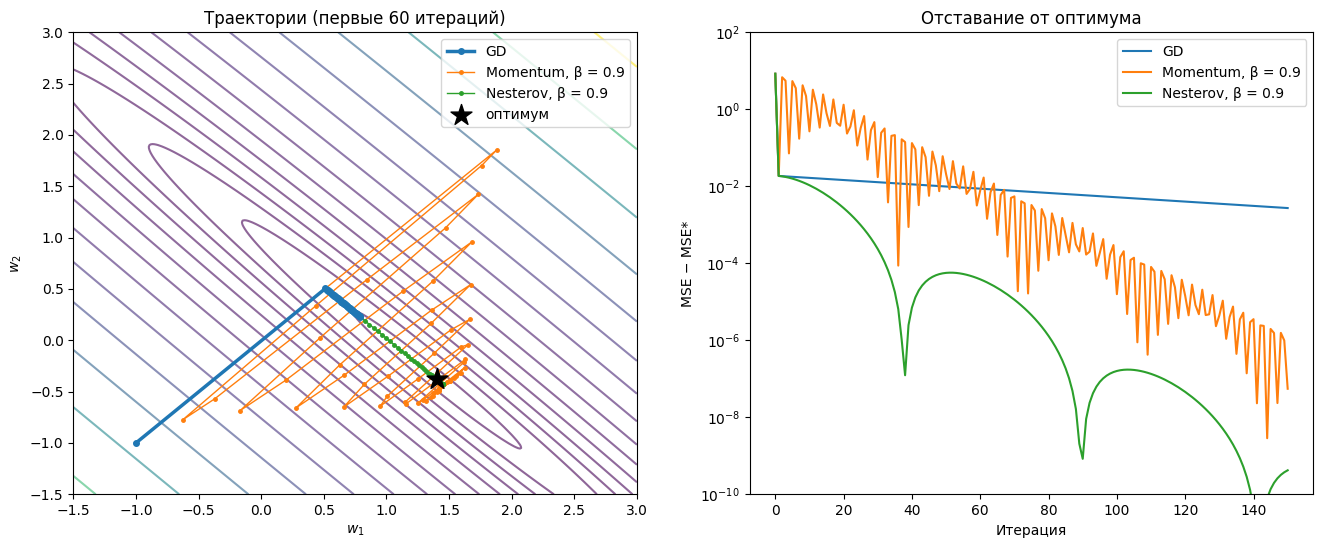

In [ ]:
configs = {
    'GD':                  dict(momentum=0.0),
    'Momentum, β = 0.9':   dict(momentum=0.9),
    'Nesterov, β = 0.9':   dict(momentum=0.9, nesterov=True),
}

w_start = [-1.0, -1.0]
models2 = {name: GDRegressor(learning_rate=1 / L2, n_iter=150, fit_intercept=False, **params).fit(X2, y2, w_init=w_start)
           for name, params in configs.items()}

# линии уровня MSE
g1, g2 = np.meshgrid(np.linspace(-1.5, 3, 300), np.linspace(-1.5, 3, 300))
W = np.stack([g1.ravel(), g2.ravel()])
Z = np.mean((X2 @ W - y2[:, None]) ** 2, axis=0).reshape(g1.shape)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

axes[0].contour(g1, g2, Z, levels=np.logspace(-1, 1.3, 15), cmap='viridis', alpha=0.6)
styles = {'GD': dict(lw=2.5, ms=4, zorder=4), 'Momentum, β = 0.9': dict(lw=1, ms=2.5), 'Nesterov, β = 0.9': dict(lw=1, ms=2.5)}
for name, mdl in models2.items():
    path = mdl.weights_history_[:60]
    axes[0].plot(path[:, 0], path[:, 1], 'o-', label=name, **styles[name])
axes[0].scatter(*w_star2, marker='*', s=250, c='black', zorder=3, label='оптимум')
axes[0].set_xlabel('$w_1$'); axes[0].set_ylabel('$w_2$')
axes[0].set_title('Траектории (первые 60 итераций)')
axes[0].legend()

best2 = np.mean((X2 @ w_star2 - y2) ** 2)
for name, mdl in models2.items():
    axes[1].plot(mdl.loss_history_ - best2 + 1e-16, label=name)
axes[1].set_yscale('log')
axes[1].set_ylim(1e-10, 1e2)
axes[1].set_xlabel('Итерация'); axes[1].set_ylabel('MSE − MSE*')
axes[1].set_title('Отставание от оптимума')
axes[1].legend()
plt.show()

* Обычный GD за один шаг спускается «на дно оврага», а потом очень медленно ползёт вдоль него — это направление с очень маленькой кривизной. За 150 итераций он так и не дошёл до оптимума.
* Momentum быстро разгоняется вдоль оврага, но при шаге $1/L$ и $\beta = 0.9$ сильно раскачивается **поперёк** него: накопленная скорость переносит точку через дно. Колебания затухают медленно, поэтому ошибка скачет.
* Nesterov считает градиент в точке «упреждения» и вовремя тормозит: поперечных колебаний почти нет, а вдоль оврага он движется так же быстро.
* С моментом ошибка **не обязана убывать монотонно** — шарик может проскочить минимум и вернуться.

Попробуйте уменьшить шаг для Momentum до $0.5/L$ или взять $\beta = 0.7$. Как меняется картина?

## Сравнение 2. Реальные данные: diabetes

Датасет `load_diabetes` из sklearn: 442 пациента, 10 признаков (возраст, ИМТ, давление и 6 показателей анализа крови). Целевая переменная — количественный показатель прогрессирования диабета через год. Анализы крови сильно коррелированы между собой, поэтому даже после стандартизации функция потерь — вытянутый овраг.

In [ ]:
from sklearn.datasets import load_diabetes
from sklearn.preprocessing import StandardScaler

Xd, yd = load_diabetes(return_X_y=True)
Xd = StandardScaler().fit_transform(Xd)

Xd1 = add_ones(Xd)
eig_d = np.linalg.eigvalsh(2 / len(yd) * Xd1.T @ Xd1)
Ld = eig_d.max()
print(f'L = {Ld:.2f}; кривизна по разным направлениям отличается в {eig_d.max() / eig_d.min():.0f} раз')

best_d = np.mean((LinearRegression().fit(Xd, yd).predict(Xd) - yd) ** 2)
print('Лучшая MSE (LinearRegression):', round(best_d, 2))

L = 8.05; кривизна по разным направлениям отличается в 470 раз
Лучшая MSE (LinearRegression): 2859.7


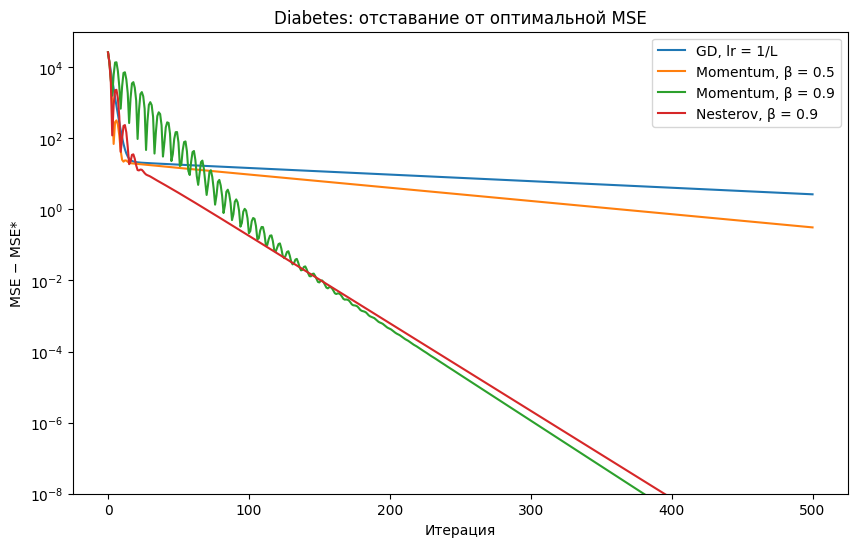

In [ ]:
configs_d = {
    'GD, lr = 1/L':                        dict(learning_rate=1 / Ld, momentum=0.0),
    'Momentum, β = 0.5':                   dict(learning_rate=1 / Ld, momentum=0.5),
    'Momentum, β = 0.9':                   dict(learning_rate=1 / Ld, momentum=0.9),
    'Nesterov, β = 0.9':                   dict(learning_rate=1 / Ld, momentum=0.9, nesterov=True),
}

models_d = {name: GDRegressor(n_iter=500, **params).fit(Xd, yd) for name, params in configs_d.items()}

plt.figure(figsize=(10, 6))
for name, mdl in models_d.items():
    plt.plot(mdl.loss_history_ - best_d + 1e-12, label=name)
plt.yscale('log')
plt.ylim(1e-8, 1e5)
plt.xlabel('Итерация')
plt.ylabel('MSE − MSE*')
plt.title('Diabetes: отставание от оптимальной MSE')
plt.legend()
plt.show()

Посчитаем, сколько итераций нужно каждому методу, чтобы подойти к оптимуму ближе чем на 0.01.

In [ ]:
for name, mdl in models_d.items():
    gap = mdl.loss_history_ - best_d
    reached = np.where(gap < 1e-2)[0]
    it = reached[0] if len(reached) else '> 500'
    print(f'{name:<32} итераций: {it}')

GD, lr = 1/L                     итераций: > 500
Momentum, β = 0.5                итераций: > 500
Momentum, β = 0.9                итераций: 149
Nesterov, β = 0.9                итераций: 152


Выводы:
* при одинаковом шаге $1/L$ метод моментов с $\beta = 0.9$ сходится в разы быстрее обычного GD;
* Nesterov обычно чуть стабильнее heavy ball: меньше «выбросов» вверх на первых итерациях;
* в глубинном обучении момент почти всегда включён: SGD с моментом 0.9 и Adam (у него момент «встроен» через параметр $\beta_1$).

# 4. Модификации градиентного спуска в sklearn

В scikit-learn нет общего набора оптимизаторов (Momentum, Adagrad, Adam и т.д.), как в PyTorch или TensorFlow. Для линейных моделей градиентные методы встречаются в двух местах:

1. **`SGDRegressor` / `SGDClassifier`** — линейные модели, обучаемые стохастическим градиентным спуском **без момента**. Как именно идёт оптимизация, задаёт параметр `learning_rate` — расписание шага (раздел 4.1).
2. **Параметр `solver`** у моделей, которые решают задачу оптимизации «целиком», прежде всего у `LogisticRegression`: `'lbfgs'`, `'newton-cg'`, `'newton-cholesky'`, `'liblinear'`, `'sag'`, `'saga'` (раздел 4.2). Здесь шаг подбирать не нужно: солвер делает это сам.

Метода моментов в линейных моделях sklearn нет, поэтому в разделе 3 мы и написали его сами.

> В старой версии этого ноутбука было написано, что у `SGDRegressor` есть параметр `momentum`, а `'optimal'` и `'adaptive'` близки к Adagrad и Adadelta. Это неверно: момента в `SGDRegressor` нет, а расписания `'optimal'` и `'adaptive'` одинаковы для всех весов, то есть не являются покоординатно-адаптивными, как Adagrad/Adadelta.

## 4.1 `SGDRegressor` / `SGDClassifier`: расписания шага `learning_rate`

Сам шаг у SGD всегда один и тот же: берём **один объект** $x_i$ и сдвигаем веса против градиента потерь на нём:

$$w \leftarrow w - \eta_t \nabla_w \ell(w; x_i, y_i).$$

Отличаются только правила, по которым меняется шаг $\eta_t$. Важная деталь: $t$ — это **номер обновления**, то есть число уже просмотренных объектов, а не номер эпохи. За одну эпоху на выборке из $m$ объектов $t$ вырастает на $m$ (в модели это хранится в атрибуте `t_`).

Почему шаг вообще нужно уменьшать? Градиент по одному объекту — шумная оценка полного градиента. С постоянным шагом SGD подходит к минимуму, но дальше «дрожит» вокруг него с амплитудой порядка шага. Чтобы сойтись точно, шаг должен убывать.

Нарисуем, как меняется шаг для каждого расписания на выборке из 100 объектов за 1000 эпох (параметры по умолчанию для `SGDRegressor`).

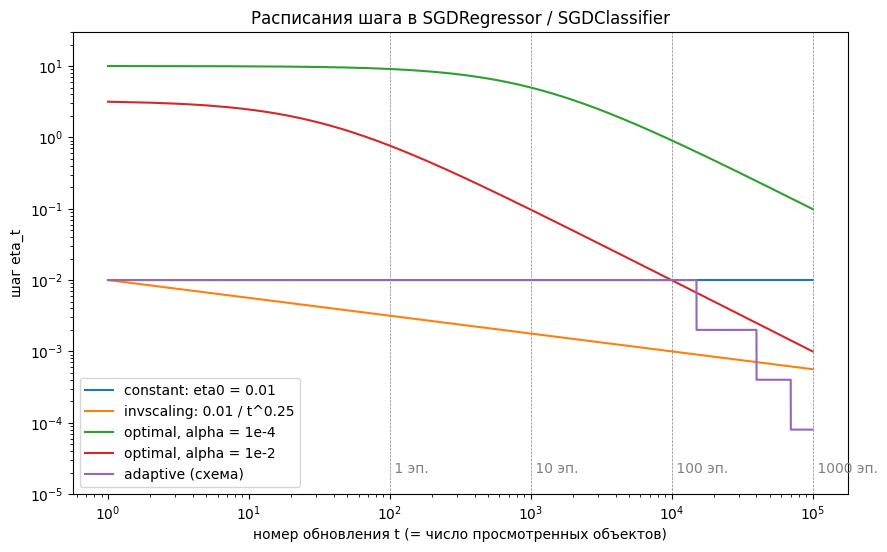

In [ ]:
m_demo = 100                       # объектов в выборке
t = np.arange(1, 1000 * m_demo + 1)  # номер обновления за 1000 эпох

eta0, power_t = 0.01, 0.25          # значения по умолчанию в SGDRegressor


def optimal_schedule(t, alpha):
    # формула из sklearn: eta = 1 / (alpha * (t0 + t - 1)), t0 подбирается эвристикой Л. Ботту
    initial_eta = (1 / np.sqrt(alpha)) ** 0.5
    t0 = 1 / (initial_eta * alpha)
    return 1 / (alpha * (t0 + t - 1))


# 'adaptive': схема. Шаг делится на 5, когда ошибка перестаёт падать;
# в какие эпохи это случится, зависит от данных — здесь моменты выбраны для иллюстрации.
adaptive = np.full(t.shape, eta0)
for epoch in [150, 400, 700]:
    adaptive[t > epoch * m_demo] /= 5

plt.figure(figsize=(10, 6))
plt.plot(t, np.full(t.shape, eta0), label="constant: eta0 = 0.01")
plt.plot(t, eta0 / t ** power_t, label="invscaling: 0.01 / t^0.25")
plt.plot(t, optimal_schedule(t, 1e-4), label="optimal, alpha = 1e-4")
plt.plot(t, optimal_schedule(t, 1e-2), label="optimal, alpha = 1e-2")
plt.plot(t, adaptive, label="adaptive (схема)")
for epoch in [1, 10, 100, 1000]:
    plt.axvline(epoch * m_demo, c="gray", lw=0.5, ls="--")
    plt.text(epoch * m_demo, 2e-5, f" {epoch} эп.", color="gray")
plt.xscale("log"); plt.yscale("log")
plt.ylim(1e-5, 30)
plt.xlabel("номер обновления t (= число просмотренных объектов)")
plt.ylabel("шаг eta_t")
plt.title("Расписания шага в SGDRegressor / SGDClassifier")
plt.legend()
plt.show()

Разберём каждое расписание.

### `'constant'`: $\eta_t = \eta_0$

Шаг не меняется. Быстро подходит к минимуму, но точно в него не попадает: веса «дрожат» вокруг оптимума, и чем больше шаг, тем сильнее.

**Когда использовать:**
* для быстрых экспериментов, когда нужно понять, учится ли модель вообще;
* при **онлайн-обучении** на потоке данных (`partial_fit`), если данные со временем меняются: модель должна продолжать подстраиваться, а убывающий шаг со временем почти «замораживает» её;
* вместе с ранней остановкой (`early_stopping=True`), если `eta0` подобран по сетке.

### `'invscaling'`: $\eta_t = \eta_0 / t^{\,power\_t}$ (по умолчанию в `SGDRegressor`)

Шаг плавно убывает. С `power_t = 0.25` убывание медленное: за 1000 эпох на 100 объектах шаг уменьшается примерно в 18 раз. Теория SGD для выпуклых задач требует более быстрого убывания (например, `power_t = 0.5`), но на практике медленное убывание часто работает лучше.

**Когда использовать:** разумный выбор по умолчанию для регрессии на стационарных данных: шум со временем уменьшается, и веса сходятся. Главный параметр — `eta0`, его стоит перебрать по логарифмической сетке. Учтите, что $t$ считает объекты: на большой выборке шаг заметно падает уже за первую эпоху.

### `'optimal'`: $\eta_t = \dfrac{1}{\alpha\,(t_0 + t)}$ (по умолчанию в `SGDClassifier`)

Шаг привязан к коэффициенту регуляризации `alpha`, а $t_0$ подбирается эвристикой так, чтобы начальный шаг был порядка $\alpha^{-1/4}$. Это расписание из теории: для сильно выпуклой функции (а L2-регуляризация делает функцию сильно выпуклой с константой $\alpha$) шаг $\sim 1/(\alpha t)$ даёт наилучшую скорость сходимости SGD.

Минус виден на графике: при маленьком `alpha` (по умолчанию `1e-4`) начальный шаг около 10, и он остаётся большим тысячи итераций. Для классификации с hinge loss или log loss это не страшно: градиент этих функций ограничен. Для квадратичной потери градиент растёт вместе с ошибкой, и метод может разойтись — ниже мы это увидим.

**Когда использовать:** `SGDClassifier` (hinge, log loss, modified huber) на стандартизованных признаках, где `alpha` вы и так подбираете как силу регуляризации. Для регрессии с MSE лучше не брать.

### `'adaptive'`: $\eta_t = \eta_0$, пока ошибка падает, затем деление на 5

Если `n_iter_no_change` эпох подряд (по умолчанию 5) ошибка на обучении не уменьшается хотя бы на `tol` (или не растёт качество на валидации при `early_stopping=True`), шаг делится на 5. Когда шаг уже опустился ниже `1e-6`, следующее плато останавливает обучение. По сути это «уменьшение шага на плато».

**Когда использовать:** надёжный вариант, когда не хочется долго подбирать расписание: можно взять довольно большой `eta0`, и метод сам уменьшит шаг, когда упрётся в шум. Хорошо сочетается с `early_stopping=True`. Работает только в `fit`, в `partial_fit` деления шага нет.

### `'pa1'` и `'pa2'` (с версии 1.8)

Это не расписания в обычном смысле, а **passive-aggressive** алгоритмы: шаг выбирается заново для каждого объекта — ровно такой, чтобы исправить ошибку на нём, но не больше `eta0`. Если объект уже предсказан хорошо, веса не меняются («пассивно»). Работают только с `loss='hinge'` в классификаторе и `loss='epsilon_insensitive'` в регрессоре.

**Когда использовать:** онлайн-обучение на потоке, когда модель обновляется по одному объекту и данные могут меняться.

### Итог

| `learning_rate` | Шаг | Сходится точно? | Когда брать |
|---|---|---|---|
| `'constant'` | $\eta_0$ | нет, дрожит около минимума | эксперименты, онлайн-обучение на меняющихся данных |
| `'invscaling'` | $\eta_0 / t^{0.25}$ | да, медленно | регрессия по умолчанию, подобрать `eta0` |
| `'optimal'` | $1/(\alpha(t_0 + t))$ | да, если `alpha` не слишком мал | `SGDClassifier` с регуляризацией |
| `'adaptive'` | $\eta_0$, затем $/5$ на плато | да | когда не хочется подбирать расписание |
| `'pa1'`, `'pa2'` | свой для каждого объекта | — | онлайн-обучение |

### Демо: постоянный шаг против убывающего

Обучим `SGDRegressor` на одномерных данных из первой части (признак стандартизуем) по одной эпохе за вызов (`partial_fit`) и будем следить, насколько MSE отстаёт от точного решения `LinearRegression`.

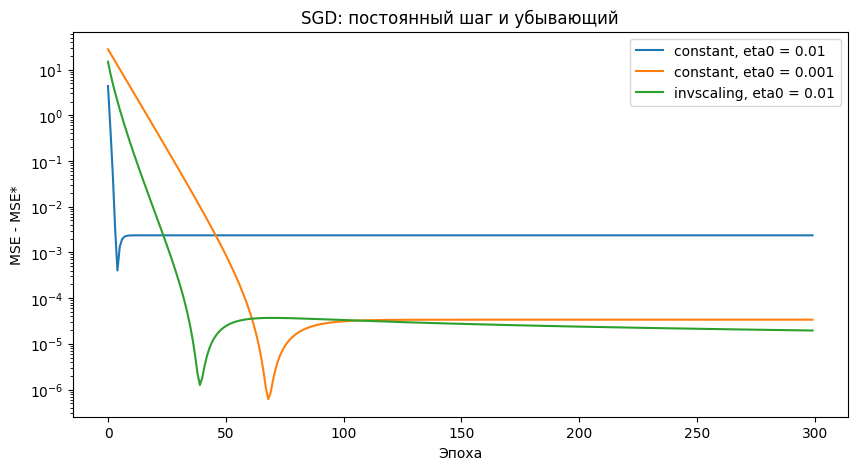

In [ ]:
from sklearn.linear_model import SGDRegressor

Xs = StandardScaler().fit_transform(X)       # одномерные данные из первой части
best_s = np.mean((LinearRegression().fit(Xs, y).predict(Xs) - y) ** 2)

sched_demo = {
    "constant, eta0 = 0.01":   dict(learning_rate="constant", eta0=0.01),
    "constant, eta0 = 0.001":  dict(learning_rate="constant", eta0=0.001),
    "invscaling, eta0 = 0.01": dict(learning_rate="invscaling", eta0=0.01),
}

plt.figure(figsize=(10, 5))
for name, params in sched_demo.items():
    sgd = SGDRegressor(alpha=0.0, random_state=0, **params)
    gap = []
    for epoch in range(300):
        sgd.partial_fit(Xs, y)               # одна эпоха SGD
        gap.append(np.mean((sgd.predict(Xs) - y) ** 2) - best_s)
    plt.plot(gap, label=name)
plt.yscale("log")
plt.xlabel("Эпоха")
plt.ylabel("MSE - MSE*")
plt.title("SGD: постоянный шаг и убывающий")
plt.legend()
plt.show()

* С постоянным шагом 0.01 ошибка за десяток эпох падает до уровня около $2\cdot10^{-3}$ и дальше не уменьшается: веса крутятся около оптимума, это «шумовой пол» SGD.
* С шагом 0.001 пол примерно в 70 раз ниже, но, чтобы до него дойти, нужно около 70 эпох.
* Убывающий шаг `invscaling` в начале медленнее большого постоянного шага, но к 50-й эпохе обгоняет оба варианта и продолжает приближаться к решению.

Резкие «провалы» на кривых — моменты, когда веса проскакивают через оптимум: ошибка на мгновение почти нулевая, а потом устанавливается на своём уровне шума.

Теперь посмотрим на ошибку по эпохам при обычном `fit`. Чтобы её увидеть, включим `verbose=1` и разберём то, что `SGDRegressor` печатает в консоль.

In [ ]:
import io
import re
from contextlib import redirect_stdout
from sklearn.linear_model import SGDRegressor


def fit_with_history(model, X, y):
    """Обучает модель с verbose=1 и возвращает среднюю ошибку на каждой эпохе."""
    buffer = io.StringIO()
    with redirect_stdout(buffer):
        model.fit(X, y)
    # строки вида '... Avg. loss: 1.379221, Objective: ...' (формат немного отличается в разных версиях)
    return [float(v) for v in re.findall(r'Avg\. loss: ([-+\deE.]+)', buffer.getvalue())]

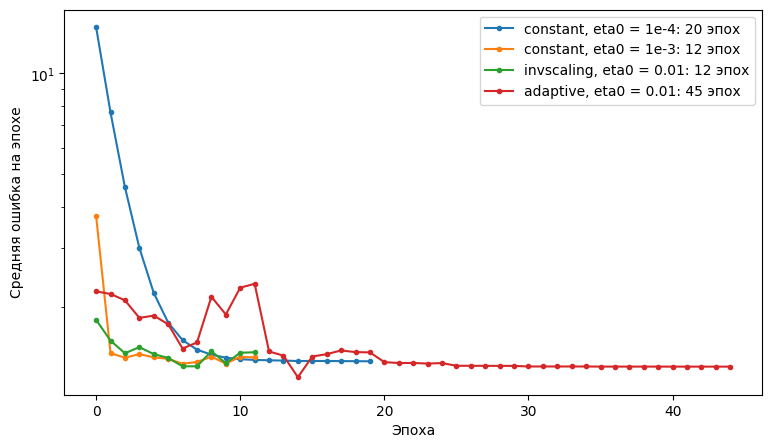

In [ ]:
schedules = {
    "constant, eta0 = 1e-4":  dict(learning_rate='constant', eta0=1e-4),
    "constant, eta0 = 1e-3":  dict(learning_rate='constant', eta0=1e-3),
    "invscaling, eta0 = 0.01": dict(learning_rate='invscaling', eta0=0.01),
    "adaptive, eta0 = 0.01":  dict(learning_rate='adaptive', eta0=0.01),
}

plt.figure(figsize=(9, 5))
for name, params in schedules.items():
    sgd = SGDRegressor(max_iter=1000, tol=1e-3, verbose=1, random_state=0, **params)
    history = fit_with_history(sgd, X, y)
    plt.plot(history, 'o-', ms=3, label=f'{name}: {len(history)} эпох')
plt.yscale('log')
plt.xlabel('Эпоха')
plt.ylabel('Средняя ошибка на эпохе')
plt.legend()
plt.show()

Обратите внимание: в `SGDRegressor` с `loss='squared_error'` потеря на объекте равна $\frac{1}{2}(a(x) - y)^2$, поэтому числа в логе вдвое меньше MSE.

Теперь попробуем `learning_rate='optimal'` на этих же данных.

In [ ]:
sgd_opt = SGDRegressor(max_iter=1000, tol=1e-3, verbose=1, learning_rate='optimal', random_state=0)
history = fit_with_history(sgd_opt, X, y)
print('Ошибка на первых эпохах:', history[:3])
print('Веса:', sgd_opt.coef_, sgd_opt.intercept_)

Ошибка на первых эпохах: [2.329009288378899e+28, 2.2193795573003164e+28, 1.7501436851528993e+28]
Веса: [1.86499646e+12] [1.5641273e+12]


Метод разошёлся: веса порядка $10^{12}$. При `alpha = 1e-4` (значение по умолчанию) начальный шаг `1 / (alpha * t0)` огромный по сравнению с $1/L$ для этих данных. Расписание `'optimal'` разумно использовать в `SGDClassifier` с регуляризацией, а для регрессии лучше брать `'invscaling'`, `'adaptive'` или `'constant'` с подобранным `eta0`.

## 4.2 `LogisticRegression`: параметр `solver`

Логистическая регрессия минимизирует log loss (плюс регуляризацию) на всей выборке. Это гладкая выпуклая функция, и sklearn решает задачу одним из шести солверов. Все они приходят к одной и той же модели, отличаются скорость, требования к памяти и поддерживаемые виды регуляризации.

Солверы удобно разделить на три группы.

### Методы второго порядка: `'newton-cg'`, `'newton-cholesky'`, `'lbfgs'`

Метод Ньютона учитывает не только градиент, но и кривизну функции — матрицу Гессе $H$ — и делает шаг $w \leftarrow w - H^{-1}\nabla Q(w)$. По сути он на каждой итерации подставляет «свою» константу Липшица по каждому направлению, поэтому овраги ему не страшны и итераций нужно очень мало (обычно единицы–десятки). Зато одна итерация дороже.

* **`'newton-cholesky'`** — «честный» метод Ньютона: строит гессиан размера $d \times d$ и решает систему разложением Холецкого. Самый быстрый, когда **объектов много, а признаков немного** (до нескольких тысяч), в том числе для one-hot признаков с редкими категориями. Память растёт как квадрат числа признаков (умноженного на число классов), поэтому для тысяч признаков он не подходит.
* **`'newton-cg'`** — тоже Ньютон, но систему с гессианом решает методом сопряжённых градиентов, не храня сам гессиан. Подходит, когда признаков больше и `'newton-cholesky'` не помещается в память.
* **`'lbfgs'`** (по умолчанию) — квазиньютоновский метод. Гессиан он вообще не считает, а приближает кривизну по тому, как менялся градиент на последних шагах. Итерации дешёвые, итераций немного. Хороший выбор по умолчанию почти для любой задачи.

Все три поддерживают только L2-регуляризацию (или её отсутствие).

### Координатный спуск: `'liblinear'`

Обновляет веса **по одной координате** за раз (алгоритм из библиотеки LIBLINEAR). Хорош на **небольших** выборках, поддерживает L1 и L2. Ограничения: только бинарная классификация (для многих классов нужна обёртка `OneVsRestClassifier`), а свободный член регуляризуется вместе с весами, что иногда немного портит модель (это поправляет параметр `intercept_scaling`).

### Стохастические методы: `'sag'`, `'saga'`

Это развитие SGD из раздела 4.1. **SAG (Stochastic Average Gradient)** тоже берёт по одному объекту, но **помнит последний градиент по каждому объекту** и шагает по их среднему. Шум от этого убывает, и метод сходится к точному решению **с постоянным шагом** — без расписаний, которые нужны обычному SGD. Шаг sklearn выбирает сам по константе Липшица градиента — той самой $L$ из раздела 2.

* **`'sag'`** — только L2.
* **`'saga'`** — улучшенный SAG, поддерживает L1 и elastic-net. Это единственный солвер для elastic-net.

Важно: сходимость `'sag'` и `'saga'` гарантирована только на признаках одного масштаба, поэтому **признаки обязательно стандартизуют**. Эти солверы рассчитаны на очень большие выборки: стоимость одной итерации не зависит от числа объектов. На данных, которые спокойно помещаются в память, методы второго порядка обычно быстрее — это видно на графике ниже.

### Итог: какой солвер выбрать

| `solver` | Метод | Регуляризация | Многоклассовая (multinomial) | Когда брать |
|---|---|---|---|---|
| `'lbfgs'` | квазиньютоновский | L2 / нет | да | по умолчанию |
| `'newton-cholesky'` | Ньютон с гессианом | L2 / нет | да | много объектов, мало признаков (в т.ч. one-hot) |
| `'newton-cg'` | Ньютон без хранения гессиана | L2 / нет | да | признаков много, нужен метод второго порядка |
| `'liblinear'` | покоординатный спуск | L1, L2 | нет (только OvR) | маленькие бинарные задачи, L1 |
| `'sag'` | SGD с памятью градиентов | L2 / нет | да | очень большие данные, признаки стандартизованы |
| `'saga'` | SAG + L1 | L1, L2, elastic-net | да | elastic-net, L1 на больших данных |

Порядок выбора на практике: начните с `'lbfgs'`; нужна L1 или elastic-net — `'saga'` (или `'liblinear'` для небольшой бинарной задачи с L1); объектов очень много, а признаков немного — `'newton-cholesky'`.

> С версии sklearn 1.8 вид регуляризации задают не параметром `penalty` (он объявлен устаревшим), а параметром `l1_ratio`: `0` — L2, `1` — L1, между ними — elastic-net. Силу регуляризации, как и раньше, задаёт `C`.

### Сравнение солверов

Обучим логистическую регрессию всеми солверами на двух выборках: небольшой `breast_cancer` (569 объектов, 30 признаков) и синтетической (200 000 объектов, 50 признаков). Признаки стандартизуем. Время зависит от компьютера, поэтому смотрите на соотношения.

breast_cancer (569 × 30)
  lbfgs            время   0.016 с, итераций   19, log loss 0.05338
  newton-cholesky  время   0.010 с, итераций    7, log loss 0.05342
  newton-cg        время   0.011 с, итераций    9, log loss 0.05339
  liblinear        время   0.012 с, итераций    8, log loss 0.05332
  sag              время   0.115 с, итераций  283, log loss 0.05347
  saga             время   0.171 с, итераций  465, log loss 0.05355
синтетика (200 000 × 50)
  lbfgs            время   0.811 с, итераций   12, log loss 0.42893
  newton-cholesky  время   0.797 с, итераций    4, log loss 0.42893
  newton-cg        время   1.294 с, итераций    5, log loss 0.42893
  liblinear        время   2.490 с, итераций    5, log loss 0.42893
  sag              время   9.553 с, итераций   31, log loss 0.42893
  saga             время   5.395 с, итераций   17, log loss 0.42893


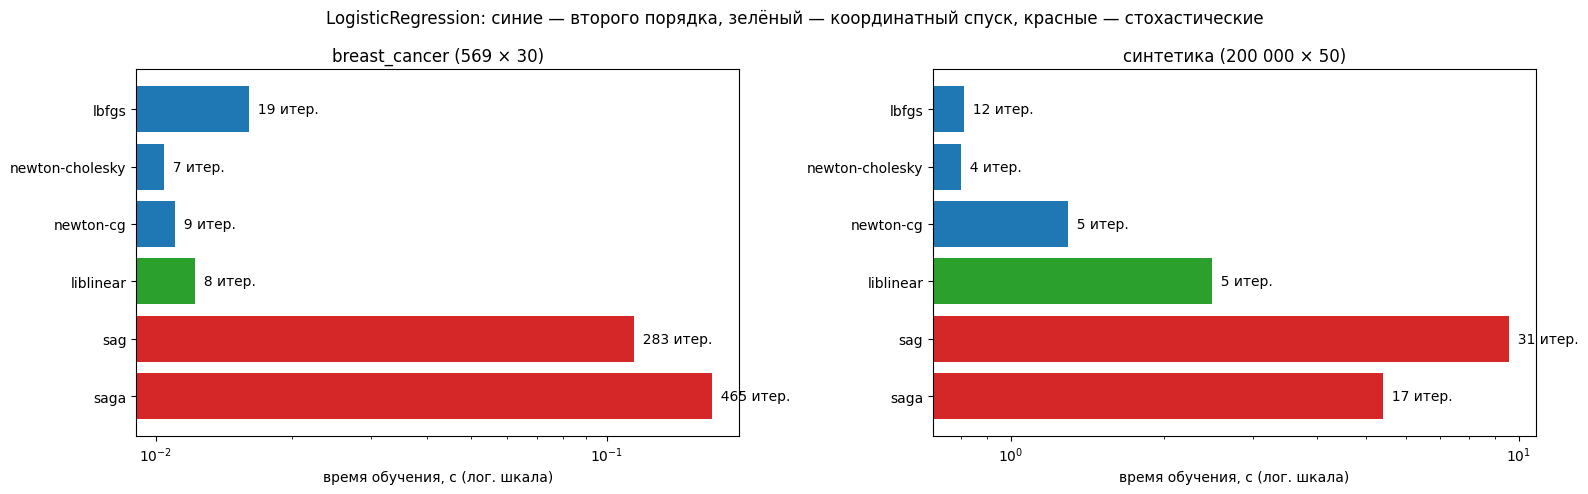

In [ ]:
import time
from sklearn.linear_model import LogisticRegression
from sklearn.datasets import load_breast_cancer, make_classification
from sklearn.metrics import log_loss

Xb, yb = load_breast_cancer(return_X_y=True)
Xs_big, ys_big = make_classification(n_samples=200_000, n_features=50, n_informative=20, random_state=0)
datasets = {
    'breast_cancer (569 × 30)':    (StandardScaler().fit_transform(Xb), yb),
    'синтетика (200 000 × 50)':    (StandardScaler().fit_transform(Xs_big), ys_big),
}
solvers = ['lbfgs', 'newton-cholesky', 'newton-cg', 'liblinear', 'sag', 'saga']

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for ax, (dname, (Xc, yc)) in zip(axes, datasets.items()):
    times, iters = [], []
    print(dname)
    for s in solvers:
        clf = LogisticRegression(solver=s, max_iter=1000)
        start = time.perf_counter()
        clf.fit(Xc, yc)
        times.append(time.perf_counter() - start)
        iters.append(int(np.max(clf.n_iter_)))
        print(f'  {s:<16} время {times[-1]:7.3f} с, итераций {iters[-1]:4d}, log loss {log_loss(yc, clf.predict_proba(Xc)):.5f}')
    bars = ax.barh(solvers, times, color=['C0', 'C0', 'C0', 'C2', 'C3', 'C3'])
    for b, it in zip(bars, iters):
        ax.text(b.get_width(), b.get_y() + b.get_height() / 2, f'  {it} итер.', va='center')
    ax.set_xscale('log')
    ax.invert_yaxis()
    ax.set_xlabel('время обучения, с (лог. шкала)')
    ax.set_title(dname)
fig.suptitle('LogisticRegression: синие — второго порядка, зелёный — координатный спуск, красные — стохастические')
plt.tight_layout()
plt.show()

* Все солверы приходят к одному и тому же решению: log loss совпадает до 3–4 знака.
* Методы второго порядка (`lbfgs`, `newton-cholesky`, `newton-cg`) обходятся единицами–десятками итераций: они учитывают кривизну функции и не мучаются с оврагами.
* `sag` и `saga` делают сотни итераций на маленькой выборке и на данных такого размера проигрывают по времени. Их ниша — очень большие (в том числе разреженные) данные и, для `saga`, L1 и elastic-net.

Проверим ещё одно утверждение: без стандартизации стохастическим солверам плохо. Возьмём `breast_cancer` без масштабирования: признаки там отличаются на порядки (от долей единицы до тысяч).

In [ ]:
import warnings
from sklearn.exceptions import ConvergenceWarning

for scaled in [False, True]:
    Xc = StandardScaler().fit_transform(Xb) if scaled else Xb
    for s in ['sag', 'lbfgs']:
        with warnings.catch_warnings():
            warnings.simplefilter('ignore', ConvergenceWarning)
            clf = LogisticRegression(solver=s, max_iter=1000).fit(Xc, yb)
        status = 'не сошёлся' if clf.n_iter_[0] >= 1000 else 'сошёлся'
        print(f"{'стандартизованные' if scaled else 'исходные':<18} {s:<6} итераций: {clf.n_iter_[0]:4d} ({status})")

исходные           sag    итераций: 1000 (не сошёлся)
исходные           lbfgs  итераций: 1000 (не сошёлся)
стандартизованные  sag    итераций:  282 (сошёлся)
стандартизованные  lbfgs  итераций:   19 (сошёлся)


На исходных признаках за 1000 итераций не сходится ни `sag`, ни даже `lbfgs`. После стандартизации `sag` сходится за несколько сотен итераций, а `lbfgs` — за пару десятков. Причина та же, что в разделе 2: большой разброс масштабов признаков даёт огромную константу Липшица и вытянутый овраг.

## Важные инсайты

* **Классический ML.** Пользуйтесь готовыми моделями и солверами. Если нужен `SGDRegressor` / `SGDClassifier`: стандартизуйте признаки, переберите `eta0` по логарифмической сетке (0.0001, 0.001, 0.01, …) и смотрите на кривую ошибки. Момент здесь не нужен.
* **Ошибка растёт или «взрывается»** — шаг больше $2/L$: уменьшите шаг и проверьте масштаб признаков.
* **Ошибка падает очень медленно** — проверьте масштаб признаков и сильно коррелированные признаки, потом пробуйте увеличить шаг.
* **`LogisticRegression`.** Начните с `solver='lbfgs'`; для L1 и elastic-net берите `'saga'`, для большого числа объектов при небольшом числе признаков — `'newton-cholesky'`. Признаки стандартизуйте всегда, а для `'sag'` и `'saga'` это обязательно.